In [1]:
import sys
sys.path.append("..")

import pandas as pd
from src.metrics import evaluate

train_df = pd.read_parquet("../data/processed/train.parquet")
print(train_df.shape)

FileNotFoundError: ../data/processed/train.parquet

In [2]:
import os
print("Thư mục hiện tại:", os.getcwd())
print("Thư mục cha có gì:", os.listdir(".."))
print()
print("data/processed có gì:")
print(os.listdir("../data/processed") if os.path.exists("../data/processed") else "KHÔNG TỒN TẠI")

Thư mục hiện tại: C:\Users\tiend\projects\bank-marketing-prediction
Thư mục cha có gì: ['bank-marketing-prediction']

data/processed có gì:
KHÔNG TỒN TẠI


In [3]:
import os
print(os.getcwd())                      # phải kết thúc bằng ...\notebooks
print(os.listdir("../data/processed"))  # phải liệt kê các file .parquet


C:\Users\tiend\projects\bank-marketing-prediction


FileNotFoundError: [WinError 3] The system cannot find the path specified: '../data/processed'

In [4]:
import os
print("Đang đứng ở:", os.getcwd())
print()

# tìm thư mục gốc repo (nơi có thư mục src), thử ở thư mục hiện tại và thư mục cha
for base in [".", ".."]:
    print(f"--- Nội dung của '{base}' ---")
    print(os.listdir(base))
    print()

# tìm mọi file .parquet trong vùng lân cận
print("--- Các file .parquet tìm được ---")
found = False
for root in [".", ".."]:
    for dirpath, dirs, files in os.walk(root):
        for f in files:
            if f.endswith(".parquet"):
                print(os.path.join(dirpath, f)); found = True
if not found:
    print("KHÔNG CÓ file .parquet nào")

Đang đứng ở: C:\Users\tiend\projects\bank-marketing-prediction

--- Nội dung của '.' ---
['.git', '.gitignore', '.ipynb_checkpoints', '02_decision_tree_rf.ipynb', 'data', 'models', 'notebooks', 'README.md', 'reports', 'requirements.txt', 'src']

--- Nội dung của '..' ---
['bank-marketing-prediction']

--- Các file .parquet tìm được ---
.\data\processed\test.parquet
.\data\processed\test_raw.parquet
.\data\processed\test_time.parquet
.\data\processed\test_with_duration.parquet
.\data\processed\train.parquet
.\data\processed\train_raw.parquet
.\data\processed\train_time.parquet
.\data\processed\train_with_duration.parquet
..\bank-marketing-prediction\data\processed\test.parquet
..\bank-marketing-prediction\data\processed\test_raw.parquet
..\bank-marketing-prediction\data\processed\test_time.parquet
..\bank-marketing-prediction\data\processed\test_with_duration.parquet
..\bank-marketing-prediction\data\processed\train.parquet
..\bank-marketing-prediction\data\processed\train_raw.parquet
.

In [5]:
import sys
import pandas as pd
from src.metrics import evaluate

train_df = pd.read_parquet("data/processed/train.parquet")
print(train_df.shape)    # kỳ vọng (32940, 65)

(32940, 65)


In [6]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from src.metrics import evaluate

RANDOM_STATE = 42

train_df = pd.read_parquet("data/processed/train.parquet")
test_df  = pd.read_parquet("data/processed/test.parquet")

X_train, y_train = train_df.drop(columns=["y"]), train_df["y"]
X_test,  y_test  = test_df.drop(columns=["y"]),  test_df["y"]

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))

(32940, 64) (8236, 64)
y
0    0.887341
1    0.112659
Name: proportion, dtype: float64


=== KẾT QUẢ ĐÁNH GIÁ: Decision Tree (baseline) (Threshold = 0.5) ===
Precision : 0.3080
Recall    : 0.3491
F1-Score  : 0.3273
ROC-AUC   : 0.6254
PR-AUC    : 0.1825

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.9159    0.9004    0.9081      7308
     Yes (1)     0.3080    0.3491    0.3273       928

    accuracy                         0.8383      8236
   macro avg     0.6120    0.6248    0.6177      8236
weighted avg     0.8474    0.8383    0.8426      8236



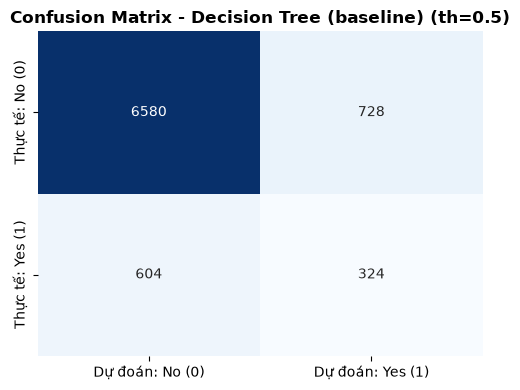

In [7]:
from sklearn.tree import DecisionTreeClassifier

results = []   # danh sách gom kết quả để làm bảng so sánh sau này

dt_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_base.fit(X_train, y_train)

prob = dt_base.predict_proba(X_test)[:, 1]
results.append(evaluate(y_test, y_prob=prob, model_name="Decision Tree (baseline)"))

=== KẾT QUẢ ĐÁNH GIÁ: Random Forest (baseline) (Threshold = 0.5) ===
Precision : 0.5436
Recall    : 0.2888
F1-Score  : 0.3772
ROC-AUC   : 0.7772
PR-AUC    : 0.4260

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.9148    0.9692    0.9412      7308
     Yes (1)     0.5436    0.2888    0.3772       928

    accuracy                         0.8925      8236
   macro avg     0.7292    0.6290    0.6592      8236
weighted avg     0.8729    0.8925    0.8777      8236



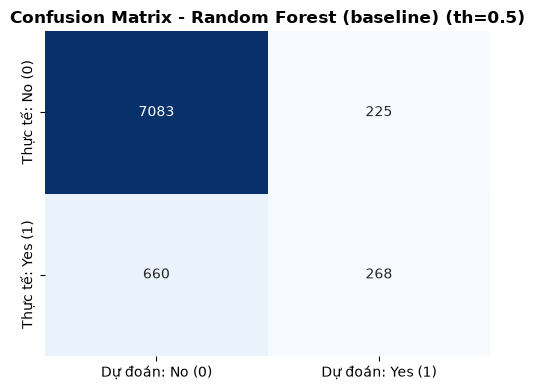

In [8]:
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)

prob = rf_base.predict_proba(X_test)[:, 1]
results.append(evaluate(y_test, y_prob=prob, model_name="Random Forest (baseline)"))

In [9]:
pd.DataFrame(results)

,Model,Threshold,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Decision Tree (baseline),0.5,0.3080,0.3491,0.3273,0.6254,0.1825,6580,728,604,324
1,Random Forest (baseline),0.5,0.5436,0.2888,0.3772,0.7772,0.4260,7083,225,660,268


In [10]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dt_params = {
    "max_depth": [3, 4, 5, 6, 8, 10, 15],
    "min_samples_leaf": [1, 5, 10, 20, 50, 100],
    "class_weight": [None, "balanced"],
}

dt_search = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_distributions=dt_params,
    n_iter=30,
    scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, verbose=1,
)
dt_search.fit(X_train, y_train)

print("Tham số tốt nhất:", dt_search.best_params_)
print("PR-AUC trung bình (CV):", round(dt_search.best_score_, 4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Tham số tốt nhất: {'min_samples_leaf': 100, 'max_depth': 10, 'class_weight': None}
PR-AUC trung bình (CV): 0.4359


In [11]:
rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [6, 8, 12, 16, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "max_features": ["sqrt", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=rf_params,
    n_iter=20,
    scoring="average_precision",
    cv=cv, n_jobs=1, random_state=RANDOM_STATE, verbose=1,
)
rf_search.fit(X_train, y_train)

print("Tham số tốt nhất:", rf_search.best_params_)
print("PR-AUC trung bình (CV):", round(rf_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Tham số tốt nhất: {'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': None}
PR-AUC trung bình (CV): 0.4692


=== KẾT QUẢ ĐÁNH GIÁ: Decision Tree (tuned) (Threshold = 0.5) ===
Precision : 0.6687
Recall    : 0.2349
F1-Score  : 0.3477
ROC-AUC   : 0.8030
PR-AUC    : 0.4686

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.9102    0.9852    0.9462      7308
     Yes (1)     0.6687    0.2349    0.3477       928

    accuracy                         0.9007      8236
   macro avg     0.7895    0.6101    0.6470      8236
weighted avg     0.8830    0.9007    0.8788      8236



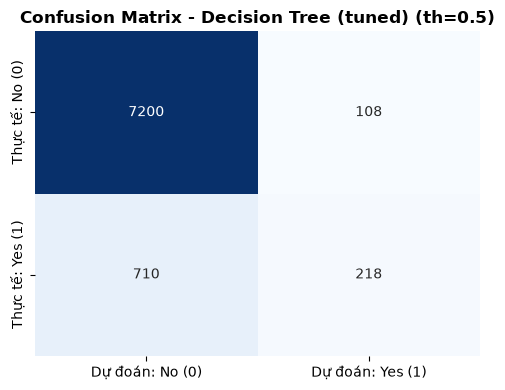

=== KẾT QUẢ ĐÁNH GIÁ: Random Forest (tuned) (Threshold = 0.5) ===
Precision : 0.6746
Recall    : 0.2435
F1-Score  : 0.3579
ROC-AUC   : 0.8121
PR-AUC    : 0.4876

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.9112    0.9851    0.9467      7308
     Yes (1)     0.6746    0.2435    0.3579       928

    accuracy                         0.9015      8236
   macro avg     0.7929    0.6143    0.6523      8236
weighted avg     0.8845    0.9015    0.8803      8236



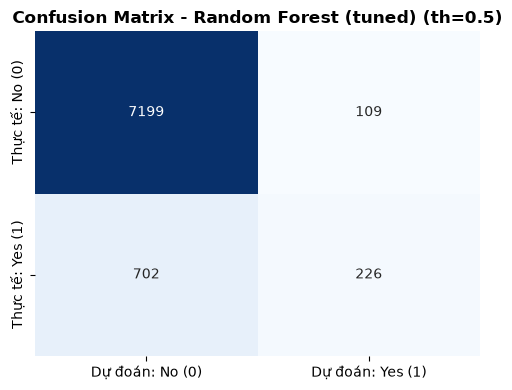

,Model,Threshold,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Decision Tree (baseline),0.5,0.3080,0.3491,0.3273,0.6254,0.1825,6580,728,604,324
1,Random Forest (baseline),0.5,0.5436,0.2888,0.3772,0.7772,0.4260,7083,225,660,268
2,Decision Tree (tuned),0.5,0.6687,0.2349,0.3477,0.8030,0.4686,7200,108,710,218
3,Random Forest (tuned),0.5,0.6746,0.2435,0.3579,0.8121,0.4876,7199,109,702,226


In [12]:
dt_best = dt_search.best_estimator_
rf_best = rf_search.best_estimator_

results.append(evaluate(y_test, y_prob=dt_best.predict_proba(X_test)[:, 1],
                        model_name="Decision Tree (tuned)"))
results.append(evaluate(y_test, y_prob=rf_best.predict_proba(X_test)[:, 1],
                        model_name="Random Forest (tuned)"))

pd.DataFrame(results)

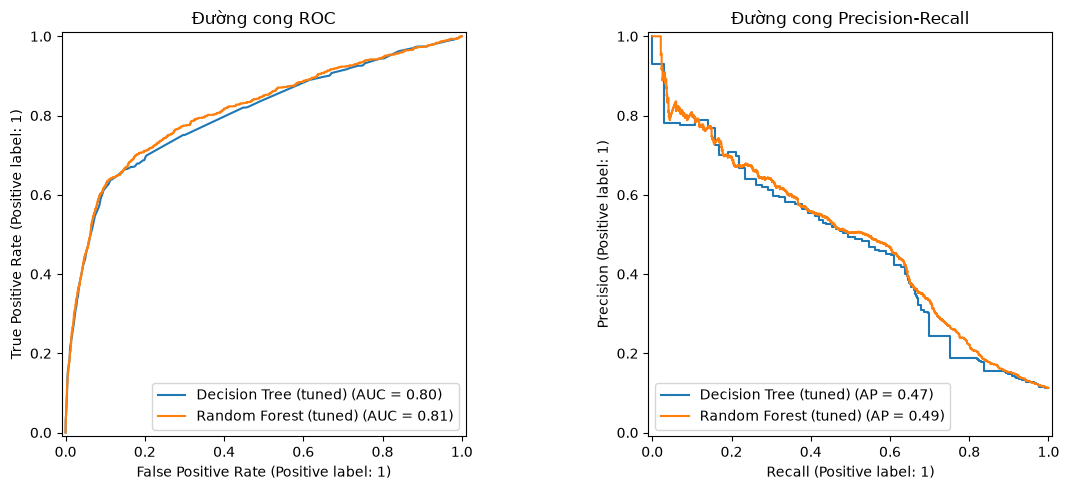

In [13]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name, model in [("Decision Tree (tuned)", dt_best), ("Random Forest (tuned)", rf_best)]:
    prob = model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=ax[1])

ax[0].set_title("Đường cong ROC")
ax[1].set_title("Đường cong Precision-Recall")
plt.tight_layout()
plt.savefig("reports/figures/tv2_roc_pr.png", dpi=150)
plt.show()

In [14]:
joblib.dump(dt_best, "models/tv2_decision_tree.joblib")
joblib.dump(rf_best, "models/tv2_random_forest.joblib")

['models/tv2_random_forest.joblib']